# Локальные эксперименты на CPU

ZIP конкурса нужен в `data/petfinder-adoption-prediction.zip` (после клонирования: `git lfs pull`).

Сначала загружаются CSV и выполняется EDA.
По умолчанию `RUN_HW1=False`: повторное обучение моделей ДЗ1 пропускается.
Чтобы его включить, `RUN_HW1=True`, набор моделей выбирается через `CONFIG_PATH`.

Для ДЗ2 JSON первого фото читаются прямо из ZIP. `INCLUDE_MEDIA=True` для этого не требуется.

In [5]:
import sys
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

candidates = [Path.cwd() / 'adoption_prediction', Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p.resolve() for p in candidates if (p / 'src/train.py').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Откройте notebook внутри репозитория adoption_prediction')
sys.path.insert(0, str(PROJECT_ROOT))

import json
import pandas as pd
import yaml
from IPython.display import display, Image
from src.prepare_data import default_data_source, resolve_data_root
from src.data import load_data
from src.eda import run_eda
from src.train import environment, run_cv, fit_submission
from src.report import build_report
from src.evaluate import group_bootstrap, save_json

print('Project:', PROJECT_ROOT)
display(environment())

Project: /Users/mac/Documents/RND_ML_course_ITMO/adoption_prediction


{'python': '3.9.6',
 'packages': {'numpy': '1.26.4',
  'pandas': '2.2.3',
  'scikit-learn': '1.5.2',
  'scipy': '1.13.1',
  'catboost': '1.2.8',
  'matplotlib': '3.9.4',
  'PyYAML': '6.0.2',
  'joblib': '1.4.2'}}

In [6]:
DATA_SOURCE = default_data_source()  # Можно заменить на путь к ZIP или папке CSV.
INCLUDE_MEDIA = False  # True — распаковать также все JPG и JSON.
# CONFIG_PATH = PROJECT_ROOT / 'configs/baseline.yaml'
CONFIG_PATH = PROJECT_ROOT / 'configs/experiments.yaml'
RUN_HW1 = False  # Включить, если нужно повторить обучение ДЗ1.
RUN_REFIT = False
RUN_DIR = PROJECT_ROOT / 'outputs' / datetime.now(ZoneInfo('Europe/Moscow')).strftime('local_%Y%m%d_%H%M%S')

CONFIG = yaml.safe_load(CONFIG_PATH.read_text())
DATA_ROOT = resolve_data_root(DATA_SOURCE, include_media=INCLUDE_MEDIA)
train, test = load_data(DATA_ROOT)
print('Data:', DATA_ROOT)
print('Output:', RUN_DIR)
print('Train:', train.shape, 'test:', test.shape)
display(CONFIG)

Data: /Users/mac/Documents/RND_ML_course_ITMO/adoption_prediction/data/raw/petfinder-adoption-prediction/2083562071-1794647197613683780
Output: /Users/mac/Documents/RND_ML_course_ITMO/adoption_prediction/outputs/local_20261116_144430
Train: (14993, 24) test: (3972, 23)


{'seed': 42,
 'split': 'stratified_group',
 'n_splits': 5,
 'models': ['dummy',
  'logreg_tabular',
  'logreg_text',
  'catboost_regressor',
  'catboost_classifier'],
 'bootstrap_repeats': 500,
 'logreg': {'C': 1.0, 'max_iter': 1500},
 'text': {'max_features': 20000},
 'catboost': {'iterations': 400,
  'depth': 6,
  'learning_rate': 0.05,
  'l2_leaf_reg': 3,
  'thread_count': 2}}

## EDA

При `INCLUDE_MEDIA=False` наличие самих изображений и JSON не проверяется, если они еще не распакованы.

{'train': {'shape': [14993, 24],
  'missing_columns': [],
  'null_counts': {'Type': 0,
   'Name': 1265,
   'Age': 0,
   'Breed1': 0,
   'Breed2': 0,
   'Gender': 0,
   'Color1': 0,
   'Color2': 0,
   'Color3': 0,
   'MaturitySize': 0,
   'FurLength': 0,
   'Vaccinated': 0,
   'Dewormed': 0,
   'Sterilized': 0,
   'Health': 0,
   'Quantity': 0,
   'Fee': 0,
   'State': 0,
   'RescuerID': 0,
   'VideoAmt': 0,
   'Description': 13,
   'PetID': 0,
   'PhotoAmt': 0,
   'AdoptionSpeed': 0},
  'empty_string_counts': {'Name': 1265, 'Description': 13},
  'duplicate_rows': 0,
  'duplicate_pet_ids': 0,
  'repeated_nonempty_descriptions': 973,
  'nonempty_descriptions_with_non_ascii': 597,
  'invalid_code_counts': {'Type': 0,
   'Gender': 0,
   'MaturitySize': 0,
   'FurLength': 0,
   'Health': 0,
   'Vaccinated': 0,
   'Dewormed': 0,
   'Sterilized': 0},
  'negative_numeric_counts': {'Age': 0,
   'Quantity': 0,
   'Fee': 0,
   'VideoAmt': 0,
   'PhotoAmt': 0},
  'non_numeric_counts': {'Age': 0,
 

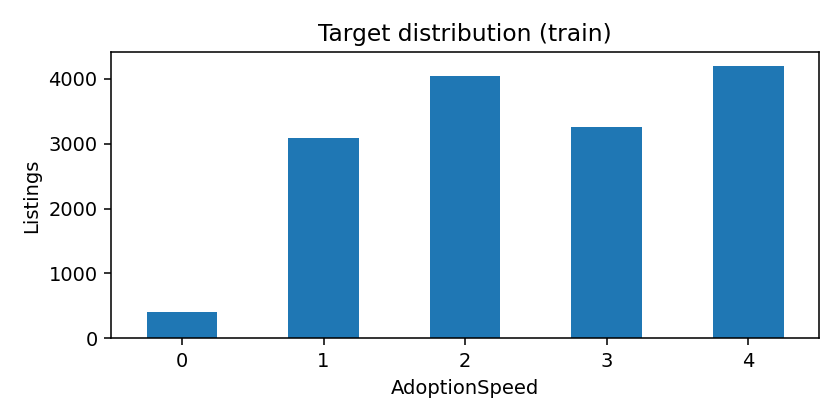

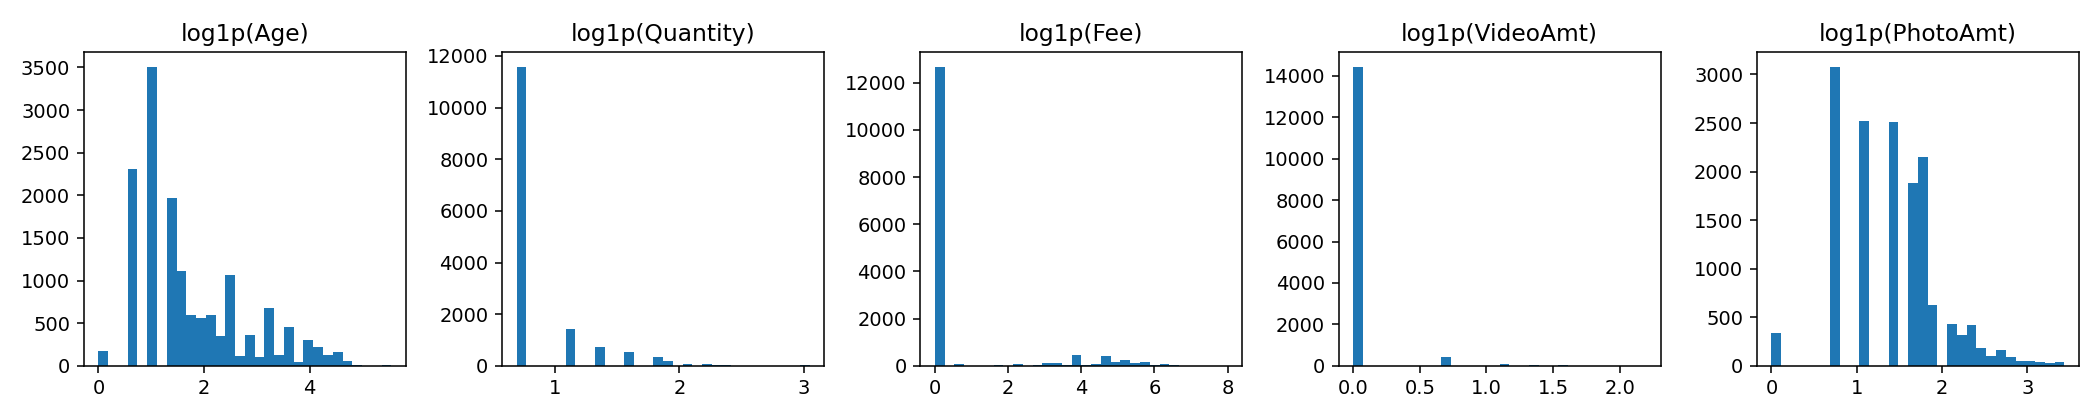

In [7]:
audit = run_eda(train, test, RUN_DIR / 'eda', DATA_ROOT)
display(audit)
display(Image(filename=str(RUN_DIR / 'eda/class_distribution.png')))
display(Image(filename=str(RUN_DIR / 'eda/numeric_distributions.png')))

In [8]:
if RUN_HW1:
    summary = run_cv(train, CONFIG, RUN_DIR / 'experiments')
    display(summary)
    report_path = build_report(RUN_DIR / 'experiments')
    print('Report:', report_path)
    display(Image(filename=str(RUN_DIR / 'experiments/model_comparison.png')))
    best_model = summary.iloc[0]['model']
    display(Image(filename=str(RUN_DIR / 'experiments' / best_model / 'confusion_matrix.png')))
    display(pd.read_csv(RUN_DIR / 'experiments' / best_model / 'errors.csv').head(3))
else:
    print('Обучение ДЗ1 пропущено, ниже запускается ДЗ2.')

Обучение ДЗ1 пропущено, ниже запускается ДЗ2.


## Гипотеза о тексте

Этот блок выполняется, если в конфиге есть обе Logistic Regression (tabular и text).

Интервал пересэмплирует авторов и относится к уже полученным OOF, без переобучения моделей.

In [9]:
if RUN_HW1 and {'logreg_tabular', 'logreg_text'}.issubset(set(summary.model)):
    results = RUN_DIR / 'experiments'
    text_oof = pd.read_csv(results / 'logreg_text/oof.csv')
    tab_oof = pd.read_csv(results / 'logreg_tabular/oof.csv')
    paired = text_oof.merge(tab_oof[['PetID', 'fold', 'y_true', 'prediction']],
                            on=['PetID', 'fold', 'y_true'], suffixes=('', '_tab'), validate='one_to_one')
    assert len(paired) == len(train)
    by_model = summary.set_index('model')
    result = {
        'delta_oof_qwk_text_minus_tabular': float(by_model.loc['logreg_text', 'oof_qwk'] - by_model.loc['logreg_tabular', 'oof_qwk']),
        'paired_group_bootstrap': group_bootstrap(paired, repeats=CONFIG.get('bootstrap_repeats', 500),
                                                  seed=CONFIG['seed'], other='prediction_tab'),
    }
    save_json(result, results / 'text_hypothesis.json')
    display(result)

## Refit и submission (по желанию)

Если RUN_REFIT=True, победитель локальной CV обучается на всем train и предсказывает test.

In [10]:
if RUN_HW1 and RUN_REFIT:
    sample_candidates = [DATA_ROOT / 'sample_submission.csv', DATA_ROOT / 'test/sample_submission.csv']
    sample_path = next((p for p in sample_candidates if p.is_file()), None)
    submission = fit_submission(train, test, CONFIG, best_model, RUN_DIR / 'refit', sample_path)
    display(submission.head())
    print('Submission:', RUN_DIR / 'refit/submission.csv')

## ДЗ2: веса классов и метаданные первого фото

Точка отсчета — CatBoostClassifier из ДЗ1. Проверяю два изменения при тех же параметрах деревьев:

- **Веса классов:** `SqrtBalanced` (более мягкое взвешивание в сравнении с balanced, не хочется повышать количество ложных нулей) повысит recall класса 0 хотя бы до 5% при снижении mean QWK не больше 0.01 относительно исходного CatBoost. Рост recall отдельно не означает улучшения QWK, смотрим также precision класса 0.
- **Метаданные первого фото:** признаки из Vision JSON дадут не менее +0.01 mean QWK относительно исходного CatBoost. Они могут дополнить `PhotoAmt`, который описывает только количество фотографий.

Четыре варианта: исходный CatBoost, только веса, только метаданные, оба изменения.
Две абляции — убираю из полной версии веса или метаданные.
Лучшую модель выбираю по mean fold QWK.

In [ ]:
from copy import deepcopy
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_fscore_support, precision_score
from src.data import TARGET, CLASSES, file_sha256
from src.photo_features import PHOTO_FEATURES, load_photo_features
from src.train import make_folds

HW2_CONFIG = yaml.safe_load((PROJECT_ROOT / 'configs/hw2.yaml').read_text())
HW2_DIR = PROJECT_ROOT / 'outputs' / datetime.now(ZoneInfo('Europe/Moscow')).strftime('hw2_%Y%m%d_%H%M%S_%f')
HW2_DIR.mkdir(parents=True, exist_ok=False)
RUN_HW2_REFIT = False

FOLDS_SOURCE = PROJECT_ROOT / 'reports/2026-11-08_group_cv_seed42/experiments/folds.csv'
fixed_folds, fold_diagnostics = make_folds(train, HW2_CONFIG, folds=FOLDS_SOURCE)
folds_hw2 = train[['PetID', 'RescuerID', TARGET]].assign(fold=fixed_folds)
FOLDS_PATH = HW2_DIR / 'folds.csv'
folds_hw2.to_csv(FOLDS_PATH, index=False)
save_json(fold_diagnostics, HW2_DIR / 'split_diagnostics.json')
save_json({'environment': environment(), 'folds_source': str(FOLDS_SOURCE),
           'folds_sha256': file_sha256(FOLDS_SOURCE), 'data_source': str(DATA_SOURCE)},
          HW2_DIR / 'input.json')

EXPERIMENTS = [
    {'name': 'baseline', 'weights': None, 'photo_metadata': False,
     'hypothesis': 'Исходный CatBoostClassifier из ДЗ1'},
    {'name': 'weights', 'weights': 'SqrtBalanced', 'photo_metadata': False,
     'hypothesis': 'Recall класса 0 >= 0.05, delta mean QWK >= -0.01 к baseline'},
    {'name': 'metadata', 'weights': None, 'photo_metadata': True,
     'hypothesis': 'Delta mean QWK >= 0.01 к baseline'},
    {'name': 'full', 'weights': 'SqrtBalanced', 'photo_metadata': True,
     'hypothesis': 'Проверка совместного эффекта двух изменений'},
]
EXPERIMENT_CONFIGS = {}
for spec in EXPERIMENTS:
    config = deepcopy(HW2_CONFIG)
    config['features']['photo_metadata'] = spec['photo_metadata']
    if spec['weights'] is not None:
        config['catboost']['auto_class_weights'] = spec['weights']
    EXPERIMENT_CONFIGS[spec['name']] = config
save_json({'experiments': EXPERIMENTS,
           'weights_criterion': {'recall_class_0_min': 0.05, 'delta_mean_qwk_min': -0.01},
           'metadata_criterion': {'delta_mean_qwk_min': 0.01}}, HW2_DIR / 'plan.json')
print('Output:', HW2_DIR)
display(pd.DataFrame(EXPERIMENTS))
display(pd.DataFrame(fold_diagnostics))

Output: /Users/mac/Documents/RND_ML_course_ITMO/adoption_prediction/outputs/hw2_20261116_144455_839213


,name,weights,photo_metadata,hypothesis
0,baseline,None,False,Исходный CatBoostClassifier из ДЗ1
1,weights,SqrtBalanced,False,"Recall класса 0 >= 0.05, delta mean QWK >= -0...."
2,metadata,None,True,Delta mean QWK >= 0.01 к baseline
3,full,SqrtBalanced,True,Проверка совместного эффекта двух изменений


,fold,train_rows,val_rows,overlapping_rescuers,val_rows_with_train_description,train_class_counts,val_class_counts
0,0,11804,3189,0,24,"{0: 319, 1: 2478, 2: 3181, 3: 2512, 4: 3314}","{0: 91, 1: 612, 2: 856, 3: 747, 4: 883}"
1,1,11618,3375,0,44,"{0: 309, 1: 2443, 2: 3101, 3: 2443, 4: 3322}","{0: 101, 1: 647, 2: 936, 3: 816, 4: 875}"
2,2,12204,2789,0,30,"{0: 332, 1: 2478, 2: 3319, 3: 2710, 4: 3365}","{0: 78, 1: 612, 2: 718, 3: 549, 4: 832}"
3,3,12384,2609,0,38,"{0: 338, 1: 2512, 2: 3413, 3: 2754, 4: 3367}","{0: 72, 1: 578, 2: 624, 3: 505, 4: 830}"
4,4,11962,3031,0,198,"{0: 342, 1: 2449, 2: 3134, 3: 2617, 4: 3420}","{0: 68, 1: 641, 2: 903, 3: 642, 4: 777}"


### Признаки из Vision JSON

Использую только `<PetID>-1.json`: число меток, максимальный confidence, confidence меток `cat`/`dog` и средние RGB доминирующих цветов с весами `pixelFraction`.
Отсутствие файла, меток и цветов отмечается отдельными флагами, недоступные числовые значения остаются NaN.
Если список меток есть, но `cat` или `dog` в нем нет, score равен нулю.

Признаки рассчитываются отдельно для каждого объявления без target и общих статистик.
Веса классов рассчитывает CatBoost только по train-части каждого фолда.
При работе с распакованными данными нужны папки `train_metadata`/`test_metadata` в корне данных.

In [12]:
PHOTO_SOURCE = DATA_SOURCE if Path(DATA_SOURCE).is_file() else DATA_ROOT
photo_train = load_photo_features(PHOTO_SOURCE, train.PetID, split='train')
feature_dir = HW2_DIR / 'photo_features'
feature_dir.mkdir(exist_ok=True)
photo_train.to_csv(feature_dir / 'train.csv', index=False)
train_hw2 = train.join(photo_train.set_index('PetID'), on='PetID', validate='one_to_one')
photo_audit = {
    'source': str(PHOTO_SOURCE), 'rows': len(photo_train), 'photo_number': 1,
    'features': PHOTO_FEATURES,
    'missing_metadata': int(photo_train.photo_metadata_missing.sum()),
    'missing_labels': int(photo_train.photo_labels_missing.sum()),
    'missing_colors': int(photo_train.photo_colors_missing.sum()),
    'rows_without_metadata_but_with_photos': int(
        ((train_hw2.photo_metadata_missing == 1) & (train_hw2.PhotoAmt > 0)).sum()),
}
save_json(photo_audit, feature_dir / 'audit.json')
display(photo_audit)
display(photo_train[PHOTO_FEATURES].agg(['count', 'mean', 'min', 'max']).T)

train: JSON первого фото найден для 14652 из 14993 объявлений


{'source': '/Users/mac/Documents/RND_ML_course_ITMO/adoption_prediction/data/petfinder-adoption-prediction.zip',
 'rows': 14993,
 'photo_number': 1,
 'features': ['photo_metadata_missing',
  'photo_labels_missing',
  'photo_colors_missing',
  'photo_label_count',
  'photo_max_label_score',
  'photo_cat_score',
  'photo_dog_score',
  'photo_red',
  'photo_green',
  'photo_blue'],
 'missing_metadata': 341,
 'missing_labels': 343,
 'missing_colors': 341,
 'rows_without_metadata_but_with_photos': 0}

,count,mean,min,max
photo_metadata_missing,14993.0,0.022744,0.000000,1.000000
photo_labels_missing,14993.0,0.022877,0.000000,1.000000
photo_colors_missing,14993.0,0.022744,0.000000,1.000000
photo_label_count,14650.0,9.432628,1.000000,10.000000
photo_max_label_score,14650.0,0.971844,0.517198,0.995285
photo_cat_score,14650.0,0.442015,0.000000,0.995285
photo_dog_score,14650.0,0.510904,0.000000,0.992593
photo_red,14652.0,127.390570,17.695248,249.411109
photo_green,14652.0,116.609033,14.959893,244.554992
photo_blue,14652.0,105.920794,7.100156,242.917455


### Четыре эксперимента

На каждый вариант приходится пять обучений CatBoost. Параметры деревьев и фолды одинаковы.
Варианты без метаданных игнорируют все новые столбцы.
Для каждого запуска сохраняются конфиг, окружение и кодовые хеши, OOF, метрики, ошибки и графики.
`experiments.csv` обновляется после каждого готового варианта, а `status.json` показывает, завершилось ли обучение.

Эту ячейку можно выполнять без повторного запуска блоков ДЗ1. Повторное выполнение перезапишет результаты четырёх вариантов в текущем `HW2_DIR`.

In [13]:
run_rows = []
for spec in EXPERIMENTS:
    name = spec['name']
    destination = HW2_DIR / name
    destination.mkdir(exist_ok=True)
    config = EXPERIMENT_CONFIGS[name]
    save_json({**spec, 'status': 'running'}, destination / 'status.json')
    print(f"\n{name}: weights={spec['weights']}, metadata={spec['photo_metadata']}", flush=True)
    started = time.perf_counter()
    try:
        result = run_cv(train_hw2, config, destination, folds=FOLDS_PATH)
        build_report(destination)
        oof = pd.read_csv(destination / 'catboost_classifier/oof.csv')
        row = result.iloc[0].to_dict()
        row.update(experiment=name, hypothesis=spec['hypothesis'],
                   weights=spec['weights'] or 'None', photo_metadata=spec['photo_metadata'],
                   seed=config['seed'], n_splits=config['n_splits'],
                   oof_precision_class_0=float(precision_score(
                       oof.y_true, oof.prediction, labels=[0], average=None, zero_division=0)[0]),
                   total_seconds=time.perf_counter() - started)
        run_rows.append(row)
        pd.DataFrame(run_rows).to_csv(HW2_DIR / 'experiments.csv', index=False)
        save_json({**spec, 'status': 'complete'}, destination / 'status.json')
    except Exception as error:
        save_json({**spec, 'status': 'failed', 'error': str(error)}, destination / 'status.json')
        raise
hw2_summary = pd.DataFrame(run_rows)
baseline_qwk = float(hw2_summary.set_index('experiment').loc['baseline', 'qwk_mean'])
hw2_summary['delta_mean_qwk'] = hw2_summary.qwk_mean - baseline_qwk
hw2_summary.to_csv(HW2_DIR / 'experiments.csv', index=False)
display(hw2_summary[['experiment', 'qwk_mean', 'qwk_std', 'delta_mean_qwk', 'oof_macro_f1',
                     'oof_recall_class_0', 'oof_precision_class_0', 'oof_severe_error_rate', 'seconds']])


baseline: weights=None, metadata=False
catboost_classifier fold=0 QWK=0.34094313624764727
catboost_classifier fold=1 QWK=0.33357971686517207
catboost_classifier fold=2 QWK=0.3432728360943791
catboost_classifier fold=3 QWK=0.3380204784425833
catboost_classifier fold=4 QWK=0.2937455133284267

weights: weights=SqrtBalanced, metadata=False
catboost_classifier fold=0 QWK=0.34190335386786663
catboost_classifier fold=1 QWK=0.33284584326191047
catboost_classifier fold=2 QWK=0.33715012258618027
catboost_classifier fold=3 QWK=0.3386331718677359
catboost_classifier fold=4 QWK=0.29966481093950414

metadata: weights=None, metadata=True
catboost_classifier fold=0 QWK=0.3326619845939962
catboost_classifier fold=1 QWK=0.3526765958642929
catboost_classifier fold=2 QWK=0.35931893180330254
catboost_classifier fold=3 QWK=0.3427079341969743
catboost_classifier fold=4 QWK=0.30355218619002144

full: weights=SqrtBalanced, metadata=True
catboost_classifier fold=0 QWK=0.3383610782772697
catboost_classifier fol

,experiment,qwk_mean,qwk_std,delta_mean_qwk,oof_macro_f1,oof_recall_class_0,oof_precision_class_0,oof_severe_error_rate,seconds
0,baseline,0.329912,0.020539,0.000000,0.286963,0.000000,0.000000,0.268459,581.815682
1,weights,0.330039,0.017289,0.000127,0.296155,0.014634,0.088235,0.276396,622.678807
2,metadata,0.338184,0.021835,0.008271,0.289036,0.000000,0.000000,0.262122,714.897199
3,full,0.336453,0.011968,0.006541,0.298584,0.017073,0.094595,0.272594,439.860423


### Сравнения и две абляции

Сравниваем каждый вариант с исходным CatBoost. Для абляций сравниваем `full` с `metadata` (убрали веса) и с `weights` (убрали метаданные).
Положительная разница `full − вариант без компонента` означает пользу компонента в полной версии.

Mean QWK относится к фолдам. Bootstrap-интервалы ниже — для разницы pooled OOF QWK, с пересэмплированием целых авторов и без переобучения моделей.
Они описывают эти OOF-предсказания и не учитывают всю неопределённость выбора лучшего из нескольких вариантов.

In [14]:
hw2_summary = pd.read_csv(HW2_DIR / 'experiments.csv')
by_experiment = hw2_summary.set_index('experiment')
oof_by_experiment = {
    name: pd.read_csv(HW2_DIR / name / 'catboost_classifier/oof.csv')
    for name in by_experiment.index
}
comparisons = []
pairs = [('weights', 'baseline'), ('metadata', 'baseline'), ('full', 'baseline'),
         ('full', 'metadata'), ('full', 'weights')]
keys = ['PetID', 'RescuerID', 'fold', 'y_true']
for candidate, reference in pairs:
    paired = oof_by_experiment[candidate].merge(
        oof_by_experiment[reference][keys + ['prediction']], on=keys,
        suffixes=('', '_reference'), validate='one_to_one')
    if len(paired) != len(train):
        raise ValueError(f'OOF не совпали: {candidate}, {reference}')
    interval = group_bootstrap(paired, repeats=HW2_CONFIG['bootstrap_repeats'],
                               seed=HW2_CONFIG['seed'], other='prediction_reference')
    comparisons.append({
        'candidate': candidate, 'reference': reference,
        'delta_mean_qwk': by_experiment.loc[candidate, 'qwk_mean'] - by_experiment.loc[reference, 'qwk_mean'],
        'delta_oof_qwk': by_experiment.loc[candidate, 'oof_qwk'] - by_experiment.loc[reference, 'oof_qwk'],
        'bootstrap_low': interval['low'], 'bootstrap_high': interval['high'],
        'valid_repeats': interval['valid_repeats'],
        'delta_recall_class_0': by_experiment.loc[candidate, 'oof_recall_class_0'] - by_experiment.loc[reference, 'oof_recall_class_0'],
    })
comparisons = pd.DataFrame(comparisons)
comparisons.to_csv(HW2_DIR / 'comparisons.csv', index=False)
hypothesis_checks = {
    'weights_criterion_met': bool(by_experiment.loc['weights', 'oof_recall_class_0'] >= 0.05
                                 and by_experiment.loc['weights', 'delta_mean_qwk'] >= -0.01),
    'metadata_criterion_met': bool(by_experiment.loc['metadata', 'delta_mean_qwk'] >= 0.01),
    'best_experiment_by_mean_qwk': str(hw2_summary.sort_values('qwk_mean', ascending=False).iloc[0].experiment),
}
save_json(hypothesis_checks, HW2_DIR / 'hypothesis_checks.json')
display(comparisons)
display(hypothesis_checks)

class_rows = []
for name, oof in oof_by_experiment.items():
    precision, recall, f1, support = precision_recall_fscore_support(
        oof.y_true, oof.prediction, labels=CLASSES, zero_division=0)
    class_rows.extend({'experiment': name, 'class': label, 'precision': float(precision[i]),
                       'recall': float(recall[i]), 'f1': float(f1[i]), 'support': int(support[i])}
                      for i, label in enumerate(CLASSES))
class_metrics = pd.DataFrame(class_rows)
class_metrics.to_csv(HW2_DIR / 'class_metrics.csv', index=False)
display(class_metrics.pivot(index='class', columns='experiment', values='recall'))

,candidate,reference,delta_mean_qwk,delta_oof_qwk,bootstrap_low,bootstrap_high,valid_repeats,delta_recall_class_0
0,weights,baseline,0.000127,0.000555,-0.006765,0.007862,500,0.014634
1,metadata,baseline,0.008271,0.008240,-0.000623,0.017720,500,0.000000
2,full,baseline,0.006541,0.006637,-0.003141,0.015732,500,0.017073
3,full,metadata,-0.001731,-0.001602,-0.010019,0.007764,500,0.017073
4,full,weights,0.006413,0.006082,-0.002168,0.014538,500,0.002439


{'weights_criterion_met': False,
 'metadata_criterion_met': False,
 'best_experiment_by_mean_qwk': 'metadata'}

experiment,baseline,full,metadata,weights
class,,,,
0,0.000000,0.017073,0.000000,0.014634
1,0.311650,0.401942,0.306472,0.407767
2,0.420114,0.317067,0.421105,0.316572
3,0.129488,0.173673,0.133477,0.167843
4,0.658327,0.641172,0.669288,0.635692


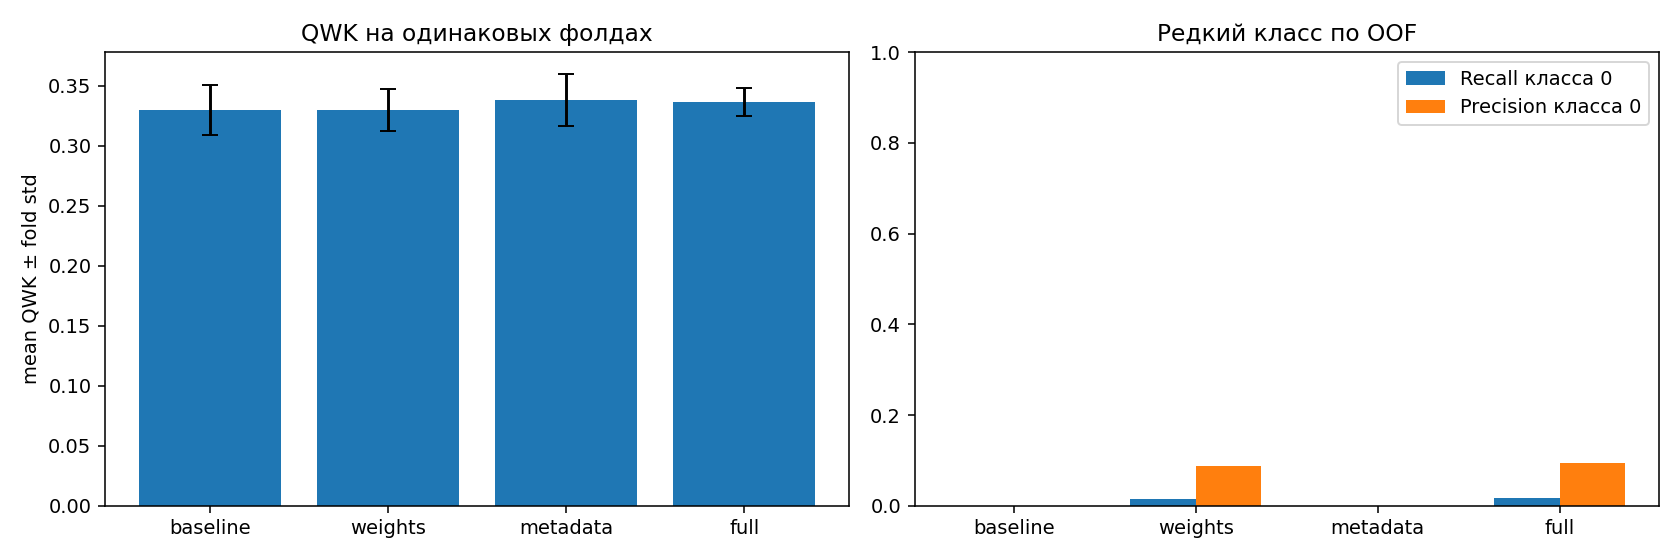

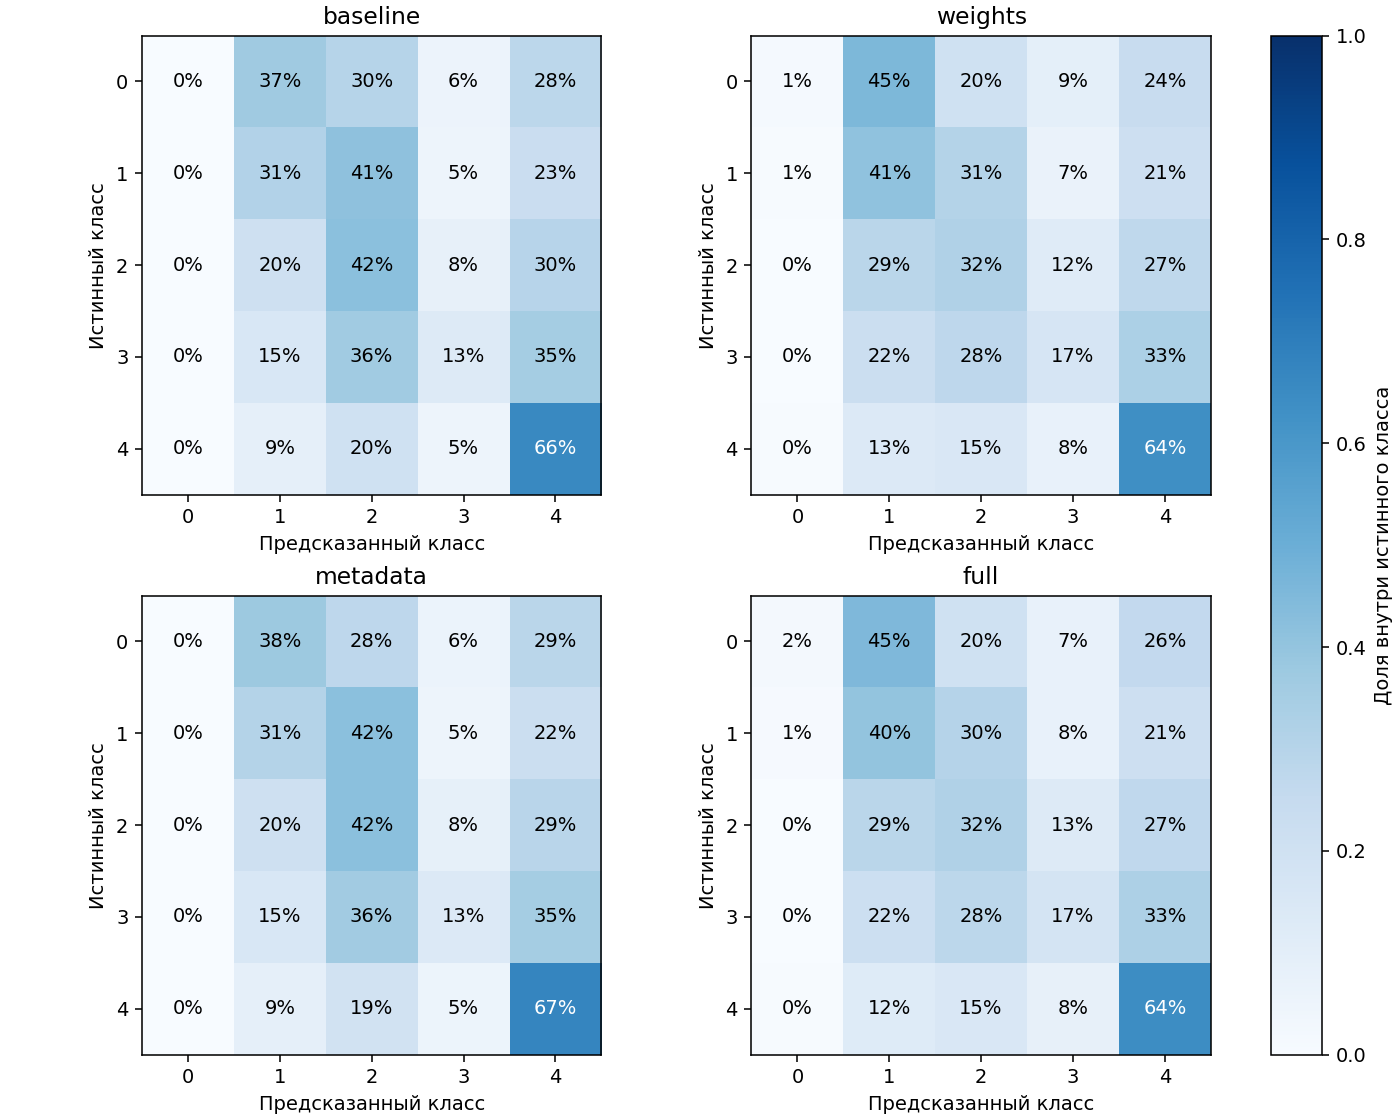

Все результаты ДЗ2: /Users/mac/Documents/RND_ML_course_ITMO/adoption_prediction/outputs/hw2_20261116_144455_839213


In [ ]:
names = [spec['name'] for spec in EXPERIMENTS]
chart = by_experiment.loc[names]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(names, chart.qwk_mean, yerr=chart.qwk_std, capsize=4)
axes[0].set(title='QWK на одинаковых фолдах', ylabel='mean QWK +- fold std')
positions = np.arange(len(names))
axes[1].bar(positions - 0.18, chart.oof_recall_class_0, width=0.36, label='Recall класса 0')
axes[1].bar(positions + 0.18, chart.oof_precision_class_0, width=0.36, label='Precision класса 0')
axes[1].set(xticks=positions, xticklabels=names, ylim=(0, 1), title='Редкий класс по OOF')
axes[1].legend()
fig.tight_layout()
fig.savefig(HW2_DIR / 'comparison.png', dpi=140)
plt.close(fig)
display(Image(filename=str(HW2_DIR / 'comparison.png')))

fig, axes = plt.subplots(2, 2, figsize=(10, 8), layout='constrained')
for ax, name in zip(axes.flat, names):
    matrix = pd.read_csv(HW2_DIR / name / 'catboost_classifier/confusion_matrix.csv', index_col=0)
    normalized = matrix.div(matrix.sum(axis=1), axis=0).fillna(0).to_numpy()
    image = ax.imshow(normalized, cmap='Blues', vmin=0, vmax=1)
    for (i, j), value in np.ndenumerate(normalized):
        ax.text(j, i, f'{value:.0%}', ha='center', va='center',
                color='white' if value > 0.5 else 'black')
    ax.set(title=name, xlabel='Предсказанный класс', ylabel='Истинный класс',
           xticks=CLASSES, yticks=CLASSES)
fig.colorbar(image, ax=axes.ravel().tolist(), label='Доля внутри истинного класса')
fig.savefig(HW2_DIR / 'confusion_matrices.png', dpi=140)
plt.close(fig)
display(Image(filename=str(HW2_DIR / 'confusion_matrices.png')))
print('Все результаты ДЗ2:', HW2_DIR)

### Refit ДЗ2 по желанию

По умолчанию выключен. В целом нужен только для submission (`RUN_HW2_REFIT` = True).
Вариант выбирается только по mean QWK на CV.

In [ ]:
if RUN_HW2_REFIT:
    best_experiment = hypothesis_checks['best_experiment_by_mean_qwk']
    best_config = EXPERIMENT_CONFIGS[best_experiment]
    test_hw2 = test.copy()
    if best_config['features']['photo_metadata']:
        photo_test = load_photo_features(PHOTO_SOURCE, test.PetID, split='test')
        photo_test.to_csv(feature_dir / 'test.csv', index=False)
        test_hw2 = test.join(photo_test.set_index('PetID'), on='PetID', validate='one_to_one')
    sample_candidates = [DATA_ROOT / 'sample_submission.csv', DATA_ROOT / 'test/sample_submission.csv']
    sample_path = next((p for p in sample_candidates if p.is_file()), None)
    submission_hw2 = fit_submission(train_hw2, test_hw2, best_config, 'catboost_classifier',
                                    HW2_DIR / 'refit', sample_path)
    save_json({'experiment': best_experiment}, HW2_DIR / 'refit/experiment.json')
    display(submission_hw2.head())
    print('Submission:', HW2_DIR / 'refit/submission.csv')